# Bài Lab: Phát hiện Góc (Corner Detection) bằng Phương pháp Harris Corner Detector

Phương pháp Harris Corner Detector là một kỹ thuật phổ biến trong thị giác máy tính để phát hiện các góc (corners) trong hình ảnh. Các góc là những điểm đặc trưng quan trọng, thường được sử dụng trong các ứng dụng như nhận dạng đối tượng, ghép nối hình ảnh (image stitching), và theo dõi đối tượng.

Trong bài lab này, chúng ta sẽ triển khai phương pháp Harris Corner Detector từ đầu, bao gồm các bước:

Tính gradient x và y của hình ảnh.
Tính ma trận cấu trúc cục bộ (structure tensor).
Tính giá trị phản hồi góc (corner response function).
Áp dụng ngưỡng (thresholding) để chọn ra các góc tiềm năng.
Sử dụng Non-Maximum Suppression (NMS) để loại bỏ các góc dư thừa.

In [1]:
!pip install matplotlib scipy numpy

1. Import các thư viện

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from scipy import ndimage
import os

chuyển đổi Hình ảnh từ RGB sang grayscale

chuyển đổi ảnh màu RGB thành ảnh grayscale bằng cách tính trung bình có trọng số của các kênh màu R, G, B.

Grayscale=0.2989×R+0.5870×G+0.1140×B

In [4]:
def rgb2gray(img):
  if rgb_image.dtype != np.float32:
        print("Warning: rgb2gray received non-float32 input, attempting conversion.")
        rgb_image = rgb_image.astype(np.float32) / 255.0 if rgb_image.dtype == np.uint8 else rgb_image.astype(np.float32)

  gray = 0.2989 * rgb_image[..., 0] + 0.5870 * rgb_image[..., 1] + 0.1140 * rgb_image[..., 2]
  return gray # Returns float32 [0,1]


hiển thị hình ảnh grayscale

In [16]:
def view_img(img_name):
  plt.figure(figsize=(8, 6))
  if img_name.ndim == 2: # Grayscale image
      plt.imshow(img_name, cmap='gray')
  else: # RGB/RGBA image
      plt.imshow(img_name) # Matplotlib expects RGB
  plt.axis('off')
  plt.show()

 tính gradient x và y bằng Sobel filter
 ### Tính Gradient Ảnh bằng Bộ Lọc Sobel

Hàm này tính đạo hàm theo hướng x và y của ảnh đầu vào bằng cách sử dụng bộ lọc Sobel, thường được sử dụng trong xử lý ảnh để tính gradient cường độ tại mỗi điểm ảnh.

Gradient của ảnh được tính theo công thức:

$$
I_x = I * S_x, \quad I_y = I * S_y
$$

Trong đó:

- $( I $) là ảnh đầu vào.
- $( S_x )$ và $( S_y )$ là các bộ lọc Sobel theo hướng x và y:

$$
S_x =
\begin{bmatrix}
-1 & 0 & 1 \\
-2 & 0 & 2 \\
-1 & 0 & 1
\end{bmatrix}
, \quad
S_y =
\begin{bmatrix}
1 & 2 & 1 \\
0 & 0 & 0 \\
-1 & -2 & -1
\end{bmatrix}
$$

### Ý nghĩa:
- $( I_x ) $ đo sự thay đổi của cường độ ảnh theo hướng ngang (biên dọc).
- $( I_y ) $ đo sự thay đổi của cường độ ảnh theo hướng dọc (biên ngang).


In [18]:
def convolveWithGaussianDerivative(img):
    scharr_x = np.array([[-3, 0, 3], [-10, 0, 10], [-3, 0, 3]], np.float32) / 16.0
    scharr_y = np.array([[3, 10, 3], [0, 0, 0], [-3, -10, -3]], np.float32) / 16.0

    Ix = ndimage.filters.convolve(img, scharr_x)
    Iy = ndimage.filters.convolve(img, scharr_y)

    return Ix, Iy

Hàm tính ma trận R  tính toán giá trị để phát hiện các góc trong ảnh
$$
R = \det(M) - k \times (\text{trace}(M))^2
$$
Trong đó, ma trận  𝑀 được định nghĩa là:

$$
M =
\begin{bmatrix}
\sum I_x^2 & \sum I_x I_y \\
\sum I_x I_y & \sum I_y^2
\end{bmatrix}
$$

In [19]:
# Hàm tính ma trận R
def Calculate_Rscore_mat(img, Iy, Ix, m, k):
    Ixx = np.square(Ix)
    Ixy = Iy * Ix
    Iyy = np.square(Iy)
    height, width = img.shape[0], img.shape[1]
    R_mat = np.zeros([height, width], dtype='float64')
    for y in range(m, height - m):
        for x in range(m, width - m):
            Kxx = Ixx[y - m:y + m + 1, x - m:x + m + 1]
            Kxy = Ixy[y - m:y + m + 1, x - m:x + m + 1]
            Kyy = Iyy[y - m:y + m + 1, x - m:x + m + 1]
            Sxx = np.sum(Kxx)
            Sxy = np.sum(Kxy)
            Syy = np.sum(Kyy)
            determinant = (Sxx * Syy) - np.square(Sxy)
            trace = Sxx + Syy
            R_mat[y][x] = determinant - (k * np.square(trace))
    return R_mat

phát hiện góc dựa trên ngưỡng (so sánh giá trị của ma trận R với một ngưỡng nhất định.)

In [20]:
# Hàm phát hiện góc dựa trên ngưỡng
def DetectCorners(img, r_mat, Th_ratio):
    corner_list = []
    Th = Th_ratio * r_mat.max()
    for y in range(img.shape[0]):
        for x in range(img.shape[1]):
            if r_mat[y][x] > Th:
                corner_list.append([y, x, r_mat[y][x]])
    return corner_list


đánh dấu vị trí góc trên hình ảnh

In [21]:
# Hàm đánh dấu góc trên hình ảnh
def MakeCornerImg(img, corner_list):
    out1 = np.zeros(img.shape, img.dtype)
    out2 = img.copy()

    for i in range(len(corner_list)):
        y = corner_list[i][0]
        x = corner_list[i][1]
        out1[y][x][0] = 1.0
        out1[y][x][1] = 1.0
        out1[y][x][2] = 1.0
        out2[y][x][0] = 1.0
        out2[y][x][1] = 0.0
        out2[y][x][2] = 0.0
    return out1, out2

Lọc các điểm góc, giữ lại các điểm có giá trị đáp ứng cao nhất trong một vùng lân cận. Loại bỏ các góc gần nhau bằng cách chỉ giữ lại góc có giá trị R lớn nhất trong một khoảng cách nhất định.

In [22]:
# Hàm áp dụng non-maximum suppression
def NonMaxSuppression(corner_list, dis):
    sorted_corner_list = sorted(corner_list, key=lambda x: x[2], reverse=True)
    final_corner_list = []
    final_corner_list.append(sorted_corner_list[0][:-1])
    xc, yc = [], []
    for i in sorted_corner_list:
        for j in final_corner_list:
            if abs(i[0] - j[0]) <= dis and abs(i[1] - j[1]) <= dis:
                break
        else:
            final_corner_list.append(i[:-1])
            xc.append(i[1])
            yc.append(i[0])
    return final_corner_list, xc, yc

xử lý từng hình ảnh

Processing paragliding.jpg


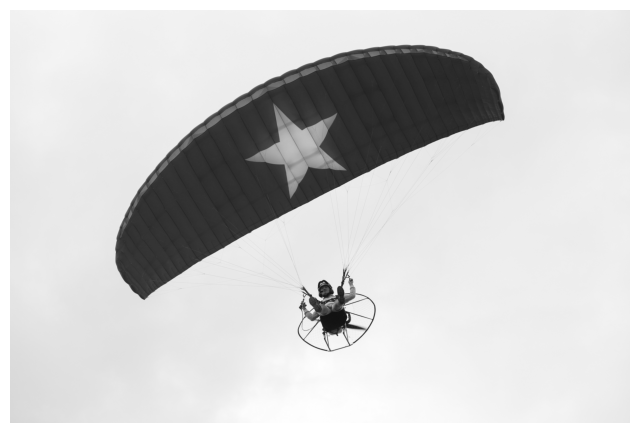

C:\Users\pc\AppData\Local\Temp\ipykernel_6928\2037279392.py:5: DeprecationWarning: Please import `convolve` from the `scipy.ndimage` namespace; the `scipy.ndimage.filters` namespace is deprecated and will be removed in SciPy 2.0.0.
  Ix = ndimage.filters.convolve(img, scharr_x)
C:\Users\pc\AppData\Local\Temp\ipykernel_6928\2037279392.py:6: DeprecationWarning: Please import `convolve` from the `scipy.ndimage` namespace; the `scipy.ndimage.filters` namespace is deprecated and will be removed in SciPy 2.0.0.
  Iy = ndimage.filters.convolve(img, scharr_y)


R-value map saved to: /content/Images Output_Scharr/paragliding_R_Value.jpg
Corners before NMS saved for paragliding.jpg
Corner pixels detected: 30418
Corner pixels detected after NMS: 1756


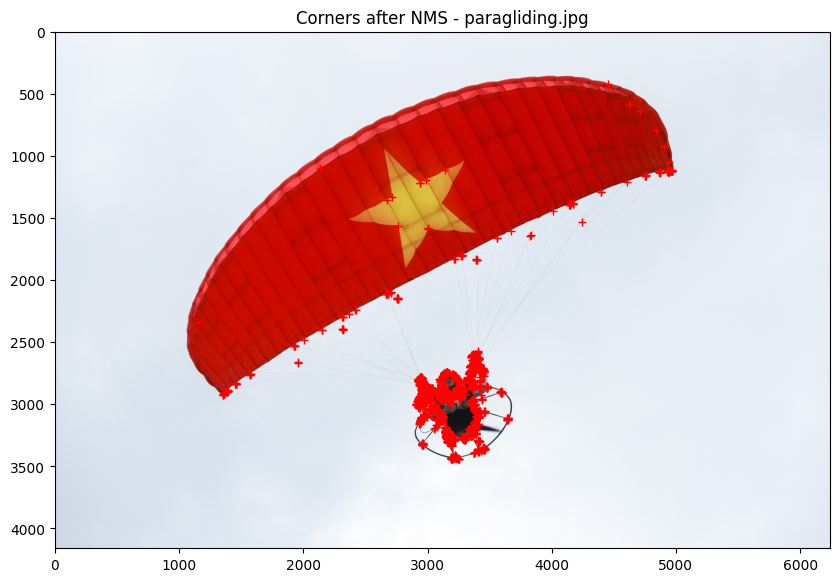

Corners marked on image saved to: /content/Images Output_Scharr/paragliding_corner_points_marked.jpg


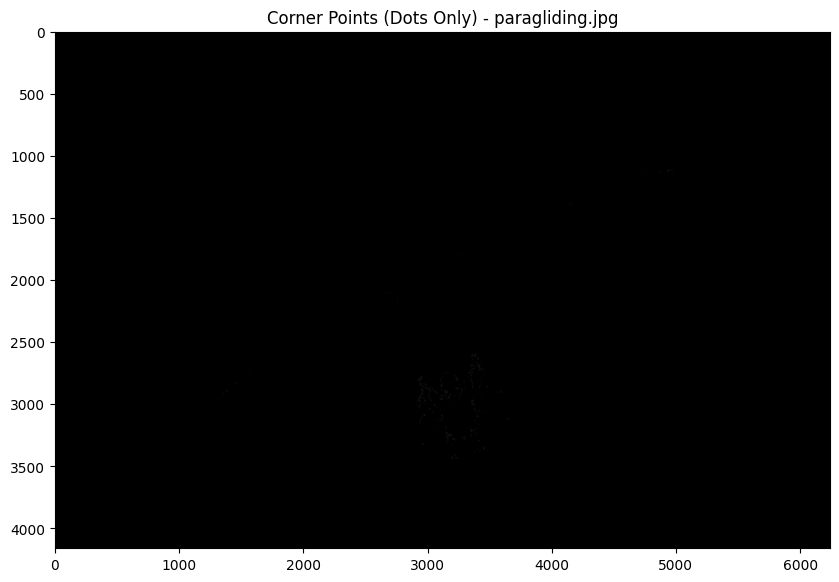

Corner dots image saved to: /content/Images Output_Scharr/paragliding_corner_points_dots.jpg
Processing horse.jpg


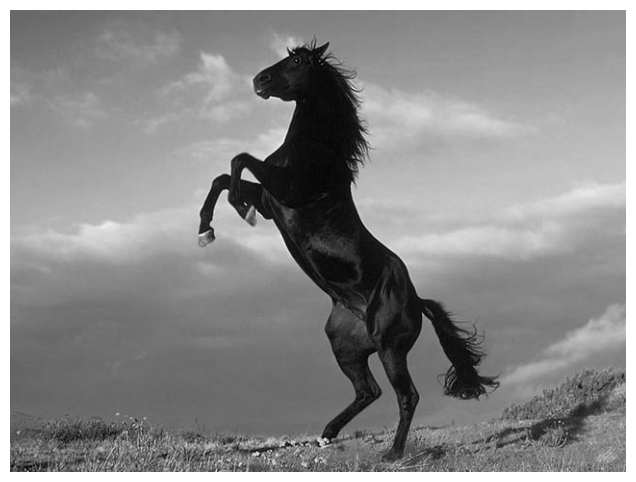

C:\Users\pc\AppData\Local\Temp\ipykernel_6928\2037279392.py:5: DeprecationWarning: Please import `convolve` from the `scipy.ndimage` namespace; the `scipy.ndimage.filters` namespace is deprecated and will be removed in SciPy 2.0.0.
  Ix = ndimage.filters.convolve(img, scharr_x)
C:\Users\pc\AppData\Local\Temp\ipykernel_6928\2037279392.py:6: DeprecationWarning: Please import `convolve` from the `scipy.ndimage` namespace; the `scipy.ndimage.filters` namespace is deprecated and will be removed in SciPy 2.0.0.
  Iy = ndimage.filters.convolve(img, scharr_y)


R-value map saved to: /content/Images Output_Scharr/horse_R_Value.jpg
Corners before NMS saved for horse.jpg
Corner pixels detected: 20374
Corner pixels detected after NMS: 1126


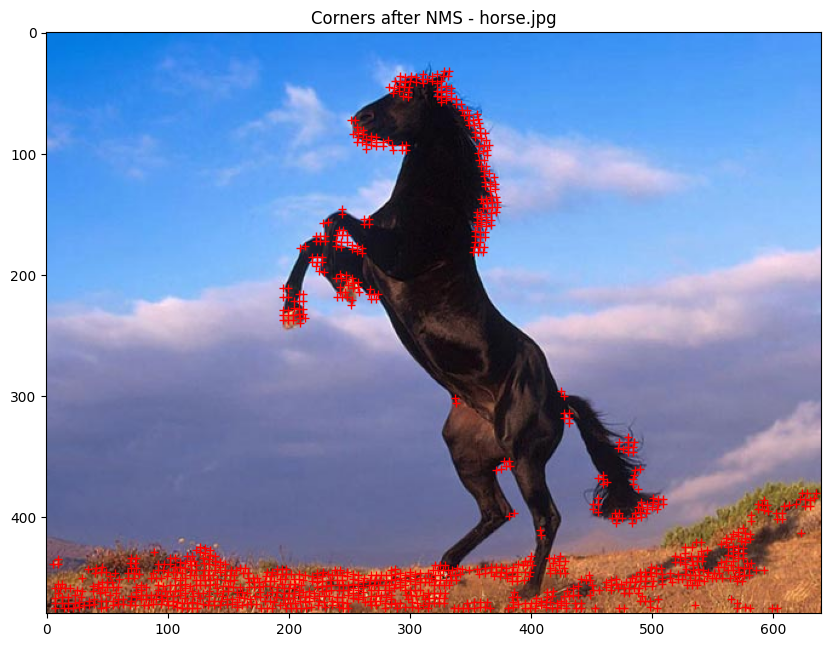

Corners marked on image saved to: /content/Images Output_Scharr/horse_corner_points_marked.jpg


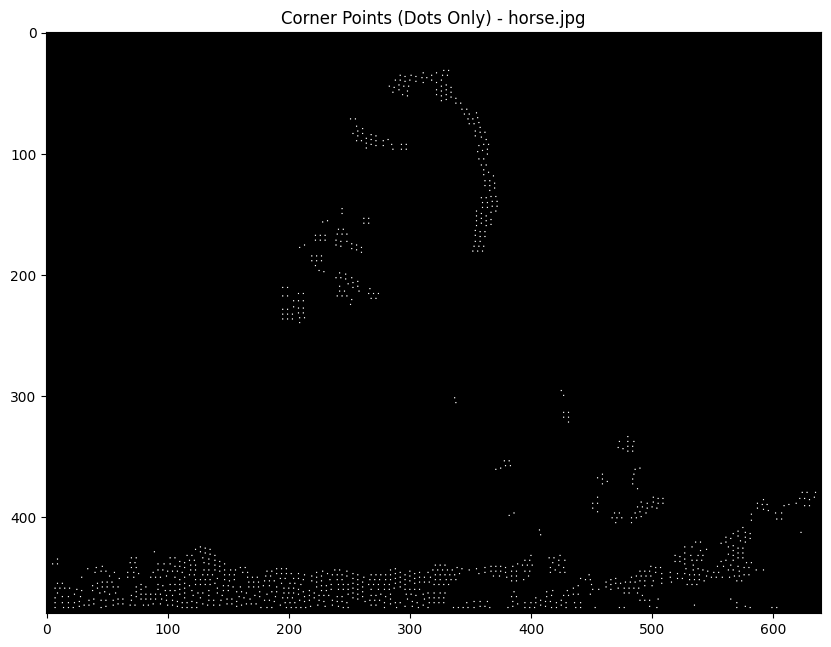

Corner dots image saved to: /content/Images Output_Scharr/horse_corner_points_dots.jpg
Processing road.jpg


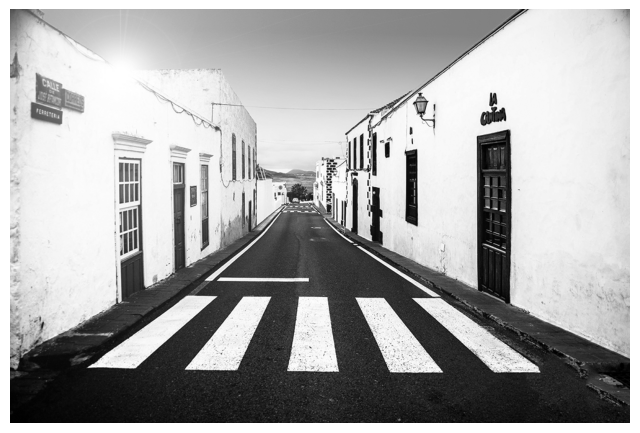

C:\Users\pc\AppData\Local\Temp\ipykernel_6928\2037279392.py:5: DeprecationWarning: Please import `convolve` from the `scipy.ndimage` namespace; the `scipy.ndimage.filters` namespace is deprecated and will be removed in SciPy 2.0.0.
  Ix = ndimage.filters.convolve(img, scharr_x)
C:\Users\pc\AppData\Local\Temp\ipykernel_6928\2037279392.py:6: DeprecationWarning: Please import `convolve` from the `scipy.ndimage` namespace; the `scipy.ndimage.filters` namespace is deprecated and will be removed in SciPy 2.0.0.
  Iy = ndimage.filters.convolve(img, scharr_y)


R-value map saved to: /content/Images Output_Scharr/road_R_Value.jpg
Corners before NMS saved for road.jpg
Corner pixels detected: 44125
Corner pixels detected after NMS: 2535


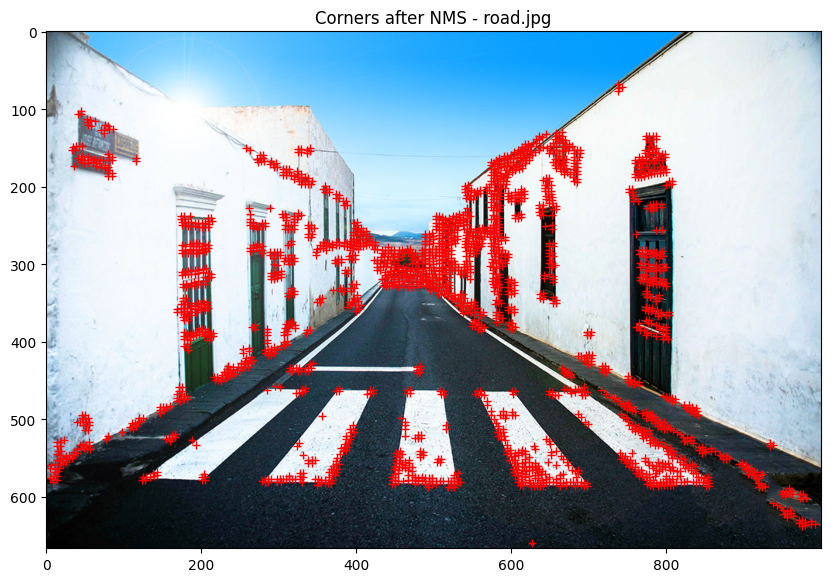

Corners marked on image saved to: /content/Images Output_Scharr/road_corner_points_marked.jpg


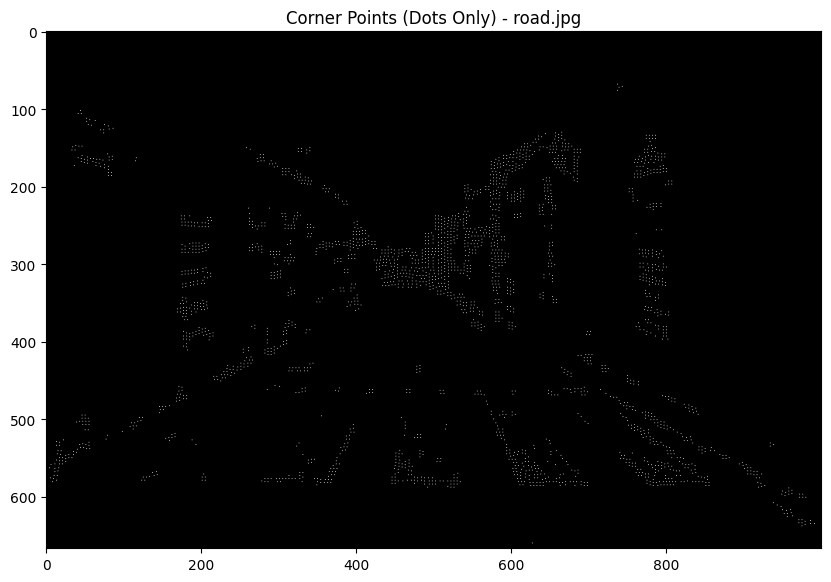

Corner dots image saved to: /content/Images Output_Scharr/road_corner_points_dots.jpg
Processing bike.jpg


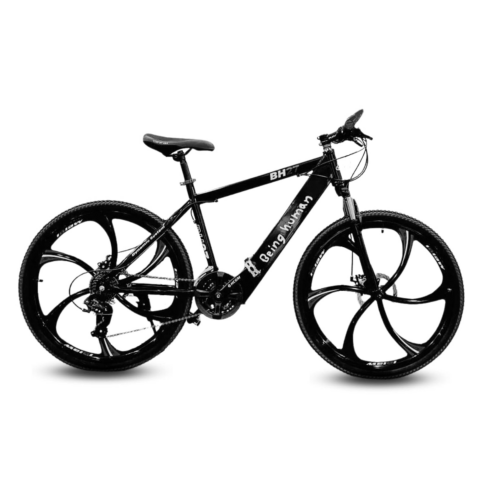

C:\Users\pc\AppData\Local\Temp\ipykernel_6928\2037279392.py:5: DeprecationWarning: Please import `convolve` from the `scipy.ndimage` namespace; the `scipy.ndimage.filters` namespace is deprecated and will be removed in SciPy 2.0.0.
  Ix = ndimage.filters.convolve(img, scharr_x)
C:\Users\pc\AppData\Local\Temp\ipykernel_6928\2037279392.py:6: DeprecationWarning: Please import `convolve` from the `scipy.ndimage` namespace; the `scipy.ndimage.filters` namespace is deprecated and will be removed in SciPy 2.0.0.
  Iy = ndimage.filters.convolve(img, scharr_y)


R-value map saved to: /content/Images Output_Scharr/bike_R_Value.jpg
Corners before NMS saved for bike.jpg
Corner pixels detected: 40534
Corner pixels detected after NMS: 2393


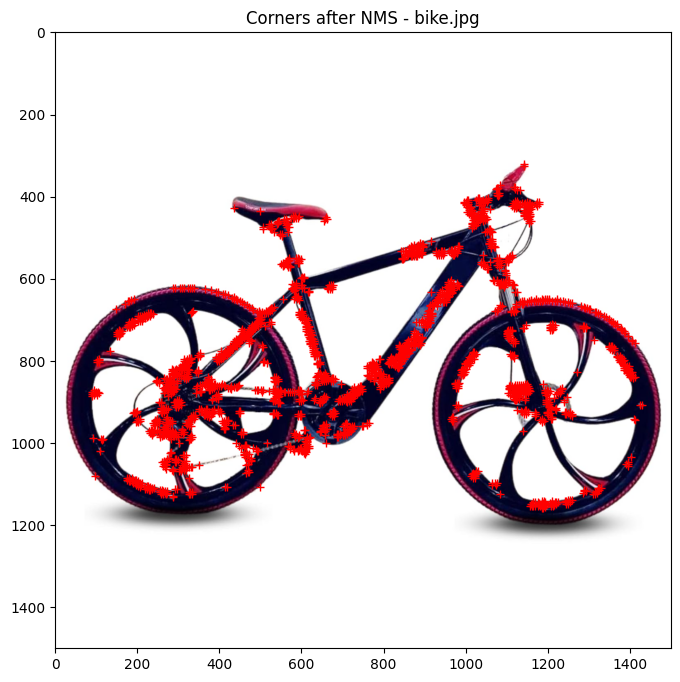

Corners marked on image saved to: /content/Images Output_Scharr/bike_corner_points_marked.jpg


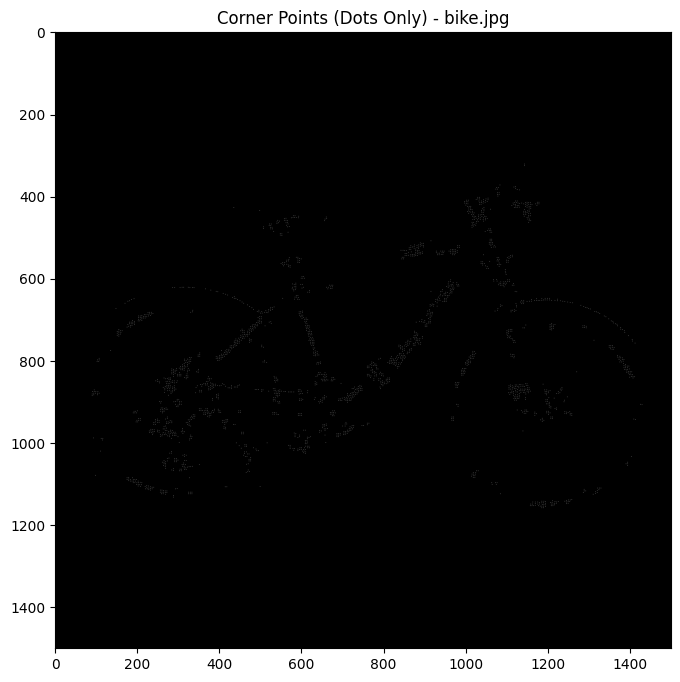

Corner dots image saved to: /content/Images Output_Scharr/bike_corner_points_dots.jpg
Processing children-like-isaac-1.jpg


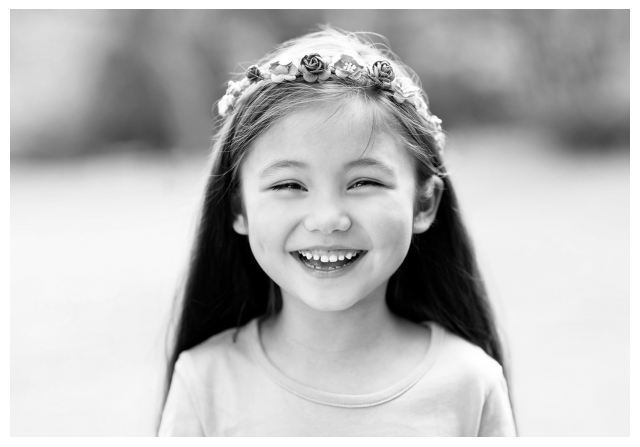

C:\Users\pc\AppData\Local\Temp\ipykernel_6928\2037279392.py:5: DeprecationWarning: Please import `convolve` from the `scipy.ndimage` namespace; the `scipy.ndimage.filters` namespace is deprecated and will be removed in SciPy 2.0.0.
  Ix = ndimage.filters.convolve(img, scharr_x)
C:\Users\pc\AppData\Local\Temp\ipykernel_6928\2037279392.py:6: DeprecationWarning: Please import `convolve` from the `scipy.ndimage` namespace; the `scipy.ndimage.filters` namespace is deprecated and will be removed in SciPy 2.0.0.
  Iy = ndimage.filters.convolve(img, scharr_y)


R-value map saved to: /content/Images Output_Scharr/children-like-isaac-1_R_Value.jpg
Corners before NMS saved for children-like-isaac-1.jpg
Corner pixels detected: 22367
Corner pixels detected after NMS: 1256


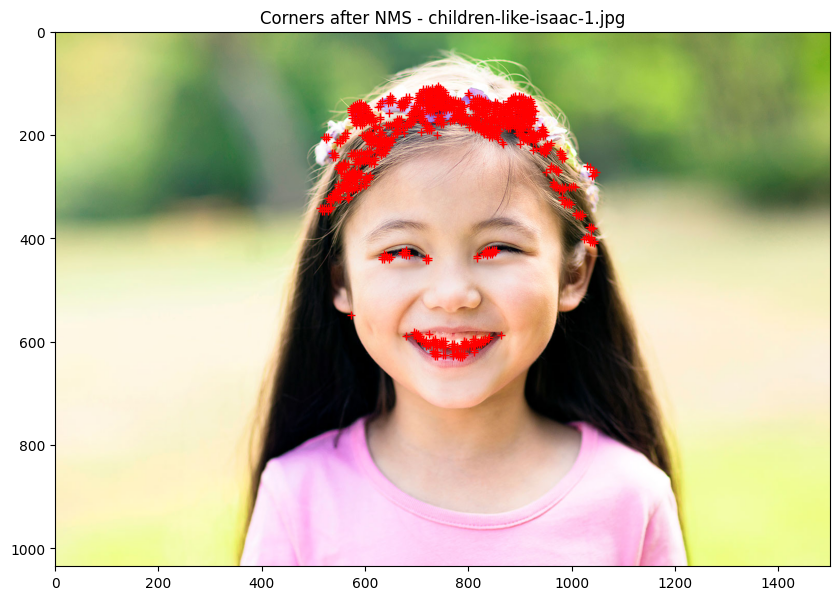

Corners marked on image saved to: /content/Images Output_Scharr/children-like-isaac-1_corner_points_marked.jpg


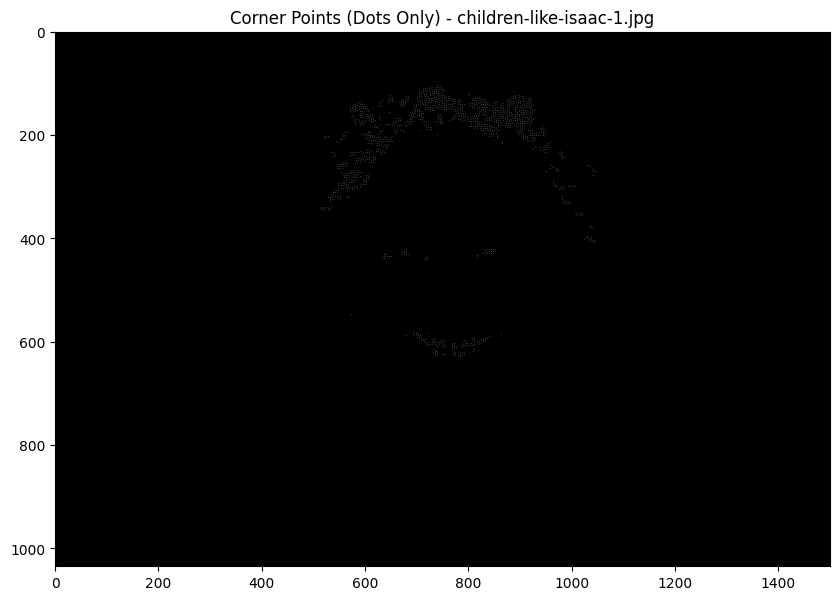

Corner dots image saved to: /content/Images Output_Scharr/children-like-isaac-1_corner_points_dots.jpg


In [23]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from skimage.color import rgb2gray

# Hàm xử lý từng hình ảnh
def GenerateResults(input_img_path, Th_ratio, output_path):
    # Use mpimg.imread directly from the provided path
    img = mpimg.imread(input_img_path).astype('float32') / 255.0
    
    gray_img = rgb2gray(img)
    print(f"Processing {os.path.basename(input_img_path)}")
    view_img(gray_img)

    # Calculate gradients
    Ix, Iy = convolveWithGaussianDerivative(gray_img)

    # Calculate R_mat (Harris response)
    # The 'm' parameter here is usually related to the window size for summing.
    # In the provided Calculate_Rscore_mat, 'm' is used for array slicing.
    # When using Gaussian smoothing, 'm' might be less critical for summing window,
    # but still important for boundary handling. Let's keep it consistent.
    R_mat = Calculate_Rscore_mat(img, Ix, Iy, m=4, k=0.04) # Pass img, Ix, Iy in correct order
    
    # Normalize R_mat for visualization and save
    temp_R = R_mat / np.max(R_mat)
    plt.imsave(f'{output_path}/{os.path.basename(input_img_path).split(".")[0]}_R_Value.jpg', temp_R, cmap=plt.get_cmap('gray'))
    print(f"R-value map saved to: {output_path}/{os.path.basename(input_img_path).split('.')[0]}_R_Value.jpg")


    # Detect corners before NMS
    corner_list = DetectCorners(img, R_mat, Th_ratio)
    out1_before_nms, out2_before_nms = MakeCornerImg(img, corner_list)
    plt.imsave(f'{output_path}/{os.path.basename(input_img_path).split(".")[0]}_corner_points_beforeNMS.jpg', out1_before_nms)
    plt.imsave(f'{output_path}/{os.path.basename(input_img_path).split(".")[0]}_corners_beforeNMS.jpg', out2_before_nms)
    print(f"Corners before NMS saved for {os.path.basename(input_img_path)}")


    # Apply NMS
    final_corner_list, xc, yc = NonMaxSuppression(corner_list, dis=3)
    print(f'Corner pixels detected: {len(corner_list)}')
    print(f'Corner pixels detected after NMS: {len(final_corner_list)}')

    # Display and save corners after NMS
    plt.figure(figsize=(10,8))
    plt.imshow(img, cmap=plt.get_cmap('gray')) # Display original image
    plt.plot(xc, yc, '+', color='red') # Plot corners
    plt.title(f"Corners after NMS - {os.path.basename(input_img_path)}")
    plt.savefig(f'{output_path}/{os.path.basename(input_img_path).split(".")[0]}_corner_points_marked.jpg')
    plt.show()
    print(f"Corners marked on image saved to: {output_path}/{os.path.basename(input_img_path).split('.')[0]}_corner_points_marked.jpg")


    corner_img_dots = np.zeros(gray_img.shape) # Create a blank image for just the dots
    for i in final_corner_list:
        y, x = i[0], i[1]
        if 0 <= y < corner_img_dots.shape[0] and 0 <= x < corner_img_dots.shape[1]:
            corner_img_dots[y][x] = 1 # White dot for corner

    plt.figure(figsize=(10,8))
    plt.imshow(corner_img_dots, cmap='gray')
    plt.title(f"Corner Points (Dots Only) - {os.path.basename(input_img_path)}")
    plt.imsave(f'{output_path}/{os.path.basename(input_img_path).split(".")[0]}_corner_points_dots.jpg', corner_img_dots, cmap='gray')
    plt.show()
    print(f"Corner dots image saved to: {output_path}/{os.path.basename(input_img_path).split('.')[0]}_corner_points_dots.jpg")

# Tạo thư mục để lưu kết quả
output_dir = '/content/Images Output_Scharr'
os.makedirs(output_dir, exist_ok=True)

# Danh sách đường dẫn hình ảnh đã tải lên
image_paths = [
    'paragliding.jpg',
    'horse.jpg',
    'road.jpg',
    'bike.jpg',
    'children-like-isaac-1.jpg'
]

# Gán ngưỡng tương ứng cho từng hình ảnh
# IMPORTANT: Adjust these thresholds (Th_ratio) based on visual inspection for optimal results.
# A higher threshold will result in fewer, stronger corners.
Th_ratio_map = {
    'paragliding.jpg': 0.01, # Example threshold
    'horse.jpg': 0.01,
    'road.jpg': 0.005, # Road might have many corners, lower threshold to capture more
    'bike.jpg': 0.05,
    'children-like-isaac-1.jpg': 0.01
}


# Xử lý từng hình ảnh
for img_path in image_paths:
    img_filename = os.path.basename(img_path)
    th = Th_ratio_map.get(img_filename, 0.01) # Get threshold from map, default to 0.01 if not found
    GenerateResults(img_path, th, output_dir)


Tạo thư mục để lưu kết quả

Xử lý từng hình ảnh

xử lý từng ảnh trong danh sách với ngưỡng tương ứng và lưu kết quả vào thư mục đã tạo.

# Phát hiện các góc Harris bằng phương pháp SIFT

# Phát hiện Góc và Đặc Trưng trong Ảnh

## 1. Mục tiêu
phát hiện các góc trong ảnh sử dụng phương pháp Harris Corner Detection kết hợp với Non-Maximum Suppression (NMS) và sử dụng thuật toán SIFT (Scale-Invariant Feature Transform) để phát hiện và mô tả các đặc trưng của ảnh.

## 2. Công thức và lý thuyết

### 2.1. Phát hiện góc Harris
Để phát hiện các góc trong ảnh, chúng ta sử dụng một ma trận phản hồi góc \( R \) được tính bằng công thức Harris:

$$
R = \text{det}(M) - k \times (\text{trace}(M))^2
$$

Trong đó:

- \( M \) là ma trận con của các đạo hàm bậc 2 trong ảnh:

$$
M =
\begin{bmatrix}
\sum I_x^2 & \sum I_x I_y \\
\sum I_x I_y & \sum I_y^2
\end{bmatrix}
$$

Với \( I_x \) và \( I_y \) là các đạo hàm của ảnh theo trục x và y.

- \( \text{det}(M) \) là định thức của ma trận \( M \), đo độ mạnh của góc tại điểm ảnh.
- \( \text{trace}(M) \) là dấu vết của ma trận \( M \), tính bằng tổng của các phần tử trên đường chéo chính.

Để tìm các góc trong ảnh, chúng ta tìm các điểm có giá trị \( R \) lớn hơn một ngưỡng xác định.

### 2.2. Non-Maximum Suppression (NMS)
Để lọc ra các góc mạnh nhất và loại bỏ các điểm không đáng tin cậy, ta sử dụng kỹ thuật Non-Maximum Suppression (NMS). Quy trình của NMS là:

1. Đối với mỗi điểm trong danh sách các góc, kiểm tra các điểm lân cận.
2. Nếu giá trị của điểm hiện tại lớn hơn tất cả các điểm lân cận, nó được giữ lại.
3. Ngược lại, điểm này bị loại bỏ.

### 2.3. Phát hiện và mô tả đặc trưng với SIFT
SIFT là một thuật toán được sử dụng để phát hiện các đặc trưng (keypoints) trong ảnh và mô tả chúng. Quá trình phát hiện keypoints trong SIFT bao gồm các bước chính sau:

1. **Phát hiện các điểm đặc trưng (keypoints):** Những điểm này thường xuất hiện tại các điểm có thay đổi mạnh về cường độ hoặc cấu trúc, chẳng hạn như các góc, các cạnh, hoặc các vùng có đặc trưng mạnh.
2. **Tính toán descriptors:** Mỗi keypoint được mô tả bởi một vector đặc trưng, giúp phân biệt các điểm đặc trưng với nhau.

Công thức mô tả đặc trưng trong SIFT:  

Mỗi điểm đặc trưng được mô tả bằng một vector descriptor, là một tập hợp các đặc tính hình học của các điểm lân cận.

## 3. Quy trình thực hiện

1. **Chuyển đổi ảnh sang grayscale:** Chuyển ảnh màu sang ảnh xám (grayscale) để dễ dàng xử lý.
2. **Tính toán các đạo hàm của ảnh:** Sử dụng bộ lọc Sobel để tính các đạo hàm \( I_x \) và \( I_y \) của ảnh.
3. **Tính ma trận phản hồi góc \( R \):** Áp dụng công thức Harris để tính toán ma trận phản hồi góc.
4. **Phát hiện các góc trong ảnh:** So sánh giá trị trong ma trận \( R \) với ngưỡng và lưu các điểm góc.
5. **Áp dụng Non-Maximum Suppression (NMS):** Lọc các góc mạnh nhất và loại bỏ các góc không đáng tin cậy.
6. **Phát hiện và mô tả các đặc trưng với SIFT:** Sử dụng SIFT để phát hiện các keypoints và tính toán descriptors cho từng keypoint.


Số góc Harris phát hiện được trong paragliding.jpg: 599


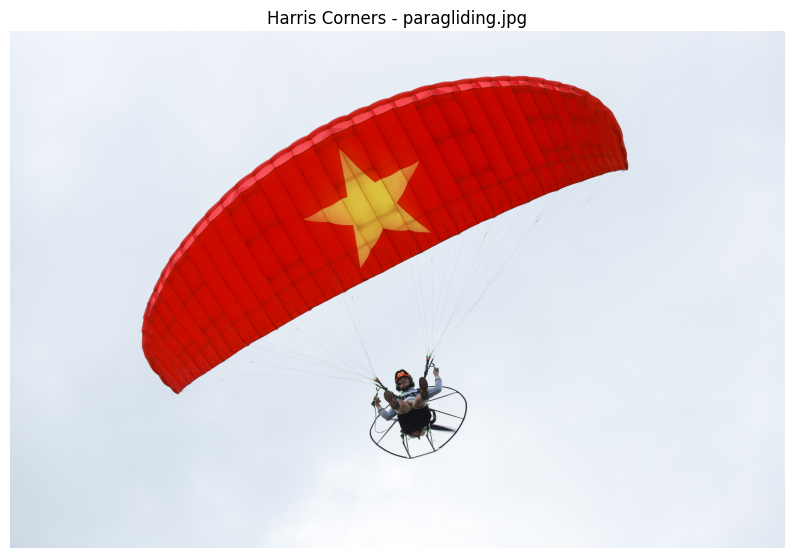

Số keypoints SIFT phát hiện được trong paragliding.jpg: 3583
Descriptors SIFT shape: (3583, 128)


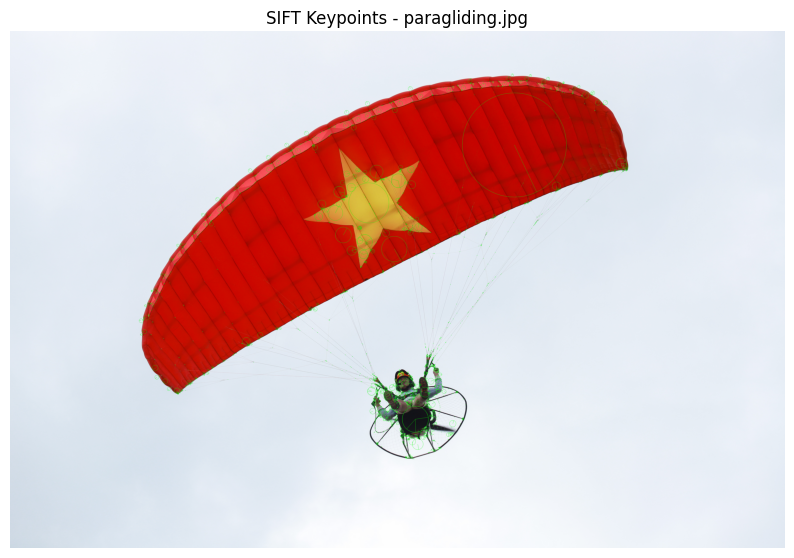

Số góc Harris phát hiện được trong horse.jpg: 577


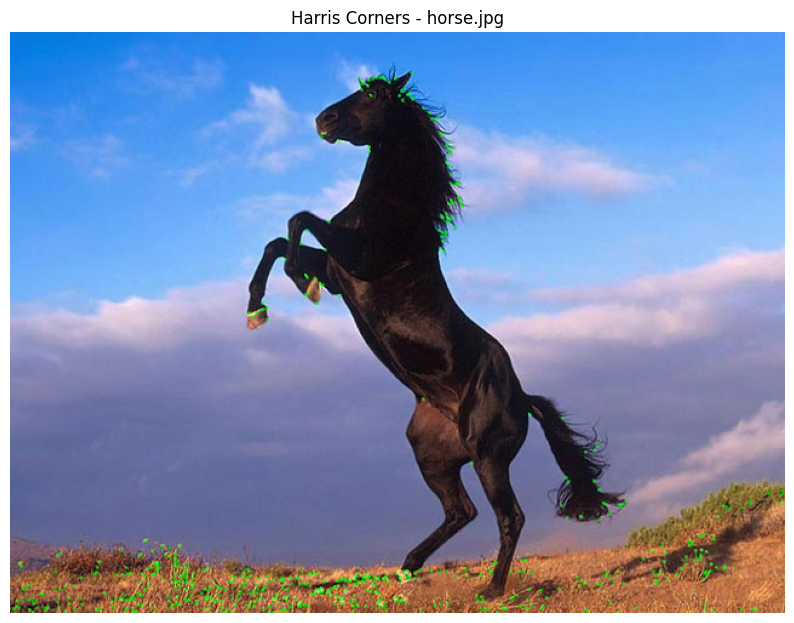

Số keypoints SIFT phát hiện được trong horse.jpg: 665
Descriptors SIFT shape: (665, 128)


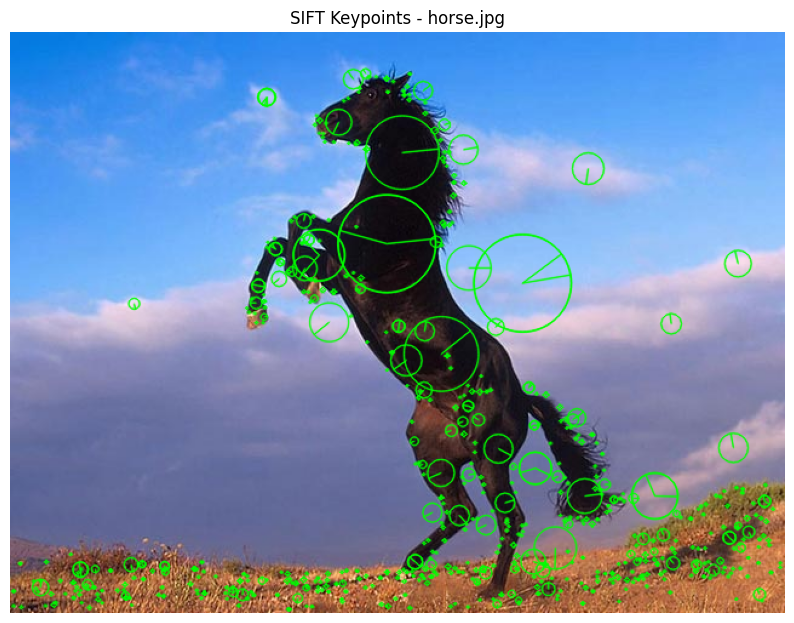

Số góc Harris phát hiện được trong road.jpg: 1383


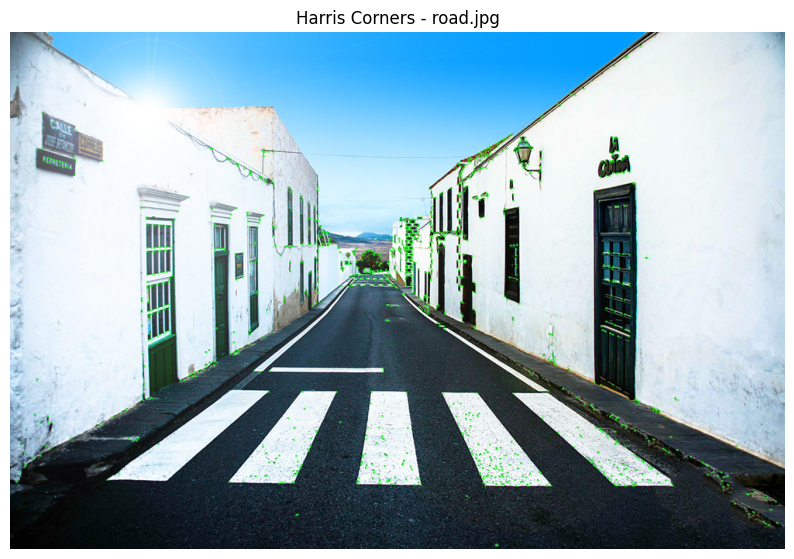

Số keypoints SIFT phát hiện được trong road.jpg: 1836
Descriptors SIFT shape: (1836, 128)


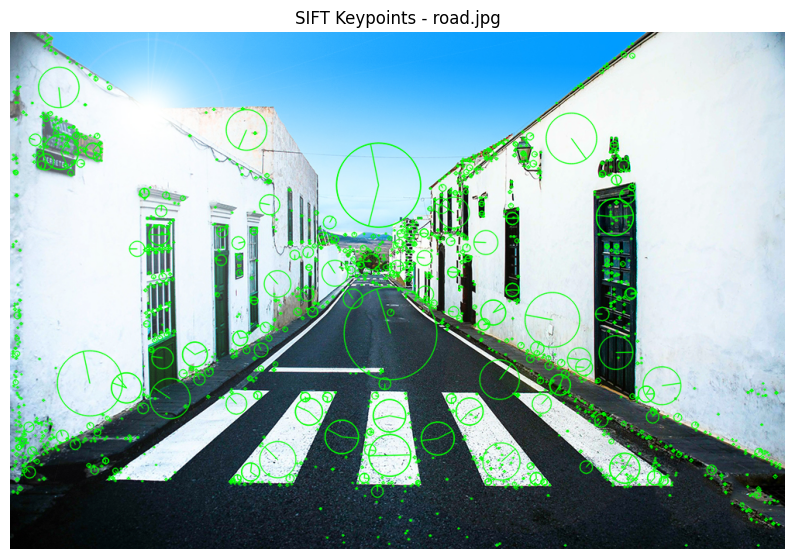

Số góc Harris phát hiện được trong bike.jpg: 2460


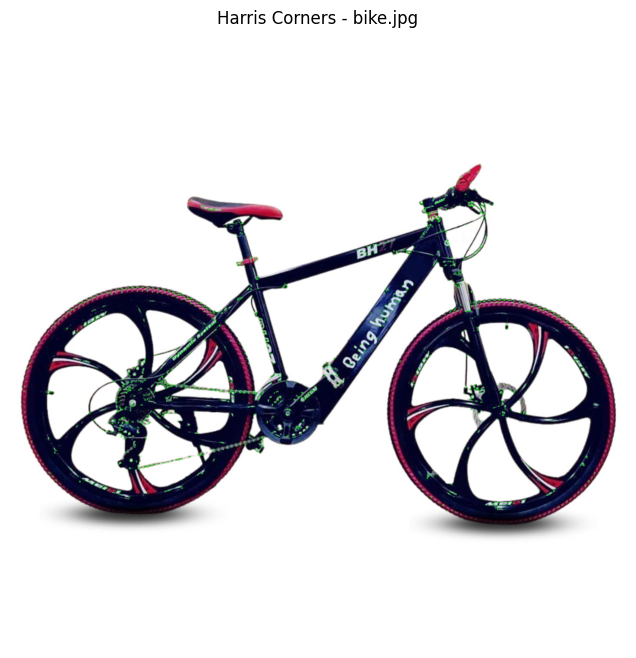

Số keypoints SIFT phát hiện được trong bike.jpg: 4512
Descriptors SIFT shape: (4512, 128)


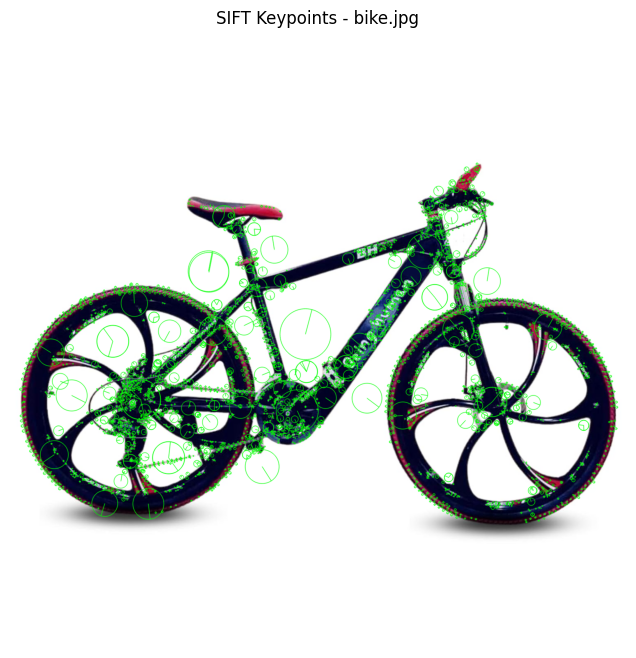

Số góc Harris phát hiện được trong children-like-isaac-1.jpg: 715


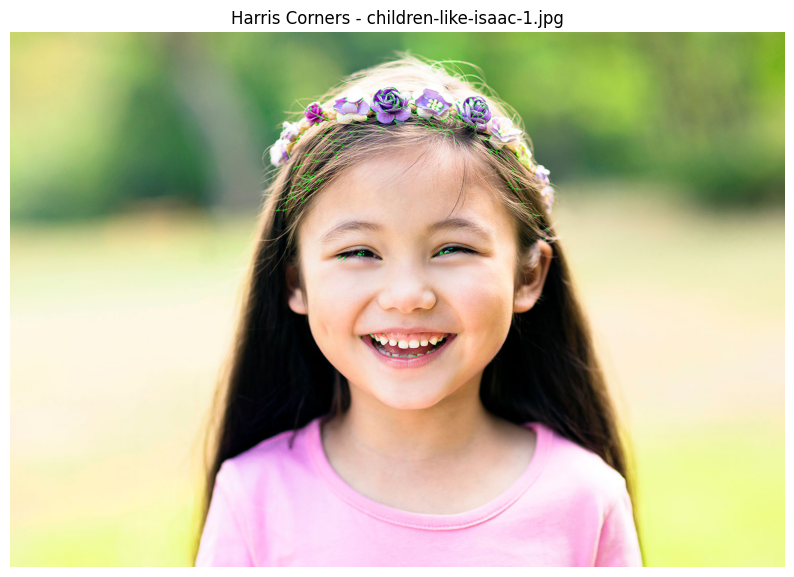

Số keypoints SIFT phát hiện được trong children-like-isaac-1.jpg: 1426
Descriptors SIFT shape: (1426, 128)


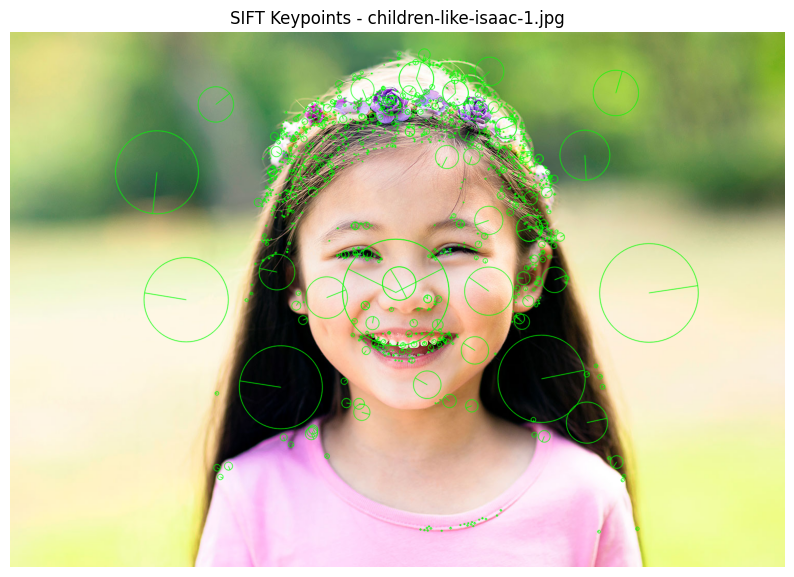

In [13]:
# Import các thư viện cần thiết
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os

# Hàm hiển thị hình ảnh với keypoints
def display_image_with_keypoints(image, keypoints, title="Keypoints"):
    img_with_keypoints = cv2.drawKeypoints(image, keypoints, None, color=(0, 255, 0), flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
    plt.figure(figsize=(10, 8))
    plt.imshow(cv2.cvtColor(img_with_keypoints, cv2.COLOR_BGR2RGB))
    plt.title(title)
    plt.axis('off')
    plt.show()

# Hàm xử lý từng hình ảnh
def DetectAndDescribeFeatures(image_path): # Removed output_path as it's not needed for displaying only
    image = cv2.imread(image_path)
    if image is None:
        print(f"Không thể đọc ảnh: {image_path}")
        return

    # Chuyển đổi ảnh sang grayscale
    gray_image = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

    # 1. Phát hiện góc Harris (tùy chọn, để minh họa)
    # Harris Corner Detection
    harris_corners = cv2.cornerHarris(gray_image, blockSize=2, ksize=3, k=0.04)

    # Áp dụng ngưỡng và Non-Maximum Suppression (thủ công cho Harris)
    threshold = 0.01 * harris_corners.max()
    harris_corner_points = []
    for y in range(harris_corners.shape[0]):
        for x in range(harris_corners.shape[1]):
            if harris_corners[y, x] > threshold:
                is_max = True
                for ny in range(max(0, y-1), min(harris_corners.shape[0], y+2)):
                    for nx in range(max(0, x-1), min(harris_corners.shape[1], x+2)):
                        if (ny != y or nx != x) and harris_corners[ny, nx] >= harris_corners[y, x]:
                            is_max = False
                            break
                    if not is_max:
                        break
                if is_max:
                    harris_corner_points.append(cv2.KeyPoint(float(x), float(y), 1))

    print(f"Số góc Harris phát hiện được trong {os.path.basename(image_path)}: {len(harris_corner_points)}")
    display_image_with_keypoints(image.copy(), harris_corner_points, f"Harris Corners - {os.path.basename(image_path)}")

    # 2. Phát hiện và mô tả đặc trưng với SIFT
    sift = cv2.SIFT_create()

    # Phát hiện keypoints và tính toán descriptors
    keypoints, descriptors = sift.detectAndCompute(gray_image, None)

    print(f"Số keypoints SIFT phát hiện được trong {os.path.basename(image_path)}: {len(keypoints)}")
    if descriptors is not None:
        print(f"Descriptors SIFT shape: {descriptors.shape}")
    else:
        print("Không có descriptors SIFT nào được tìm thấy.")

    # Hiển thị ảnh với các keypoints SIFT
    display_image_with_keypoints(image, keypoints, f"SIFT Keypoints - {os.path.basename(image_path)}")


# Danh sách đường dẫn hình ảnh đã tải lên
image_paths = [
    'paragliding.jpg',
    'horse.jpg',
    'road.jpg',
    'bike.jpg',
    'children-like-isaac-1.jpg'
]

# Xử lý từng hình ảnh
for path in image_paths:
    DetectAndDescribeFeatures(path)